# PCOS Comorbidity Risk Prediction — Classical ML vs. CNN vs. Stacking Ensemble

This notebook extends the classical-model comparison with two "can we do better"
questions:

1. **Does a CNN beat the classical models?** (Section 8)
2. **Does stacking the best classical models beat the single best one?** (Section 9)

**Spoiler, stated up front so the results below aren't a surprise:** with only
**~177 patients** and **~40 tabular clinical features with no spatial/sequential
structure**, this is a regime where tree ensembles (Random Forest, XGBoost,
Gradient Boosting) are the established strong baseline, and deep learning
architectures like CNNs typically **underperform** rather than help. A CNN's core
assumption — that nearby input positions share local structure worth convolving
over — doesn't hold for a feature vector of unrelated hormone levels, ratios, and
counts, where the *order* of the columns is arbitrary. We build and evaluate one
anyway (Section 8) so this is an empirical finding, not just an assertion, and
also test a more promising "better architecture" direction — stacking (Section 9).

**Dataset:** [PCOS dataset (Kaggle)](https://www.kaggle.com/datasets/prasoonkottarathil/polycystic-ovary-syndrome-pcos) — 541 patients, 44 clinical/biochemical features.


## 0. Setup

In [1]:
# Uncomment on Kaggle if a package is missing (usually pre-installed)
# !pip install -q imbalanced-learn xgboost tensorflow

import warnings
warnings.filterwarnings("ignore")

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score,
    f1_score, roc_curve, confusion_matrix
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
sns.set_style("whitegrid")
%matplotlib inline


I0000 00:00:1787544421.843501    6521 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1787544423.659276    6521 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1–6. Data Pipeline Recap

Same cleaning, feature engineering, target construction, and leakage-aware feature
sets as the classical-models notebook — condensed here so this notebook is
self-contained and runnable on its own.


In [2]:
KAGGLE_PATH = "/kaggle/input/datasets/mizievjoseph/pcos-project/PCOS_data.csv"
LOCAL_PATH  = "PCOS_data.csv"
DATA_PATH   = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH

df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()
df_raw.drop(columns=["Unnamed: 44", "Sl. No", "Patient File No."], errors="ignore", inplace=True)

RENAME = {
    "PCOS (Y/N)": "pcos", "Age (yrs)": "age", "Weight (Kg)": "weight_kg",
    "Height(Cm)": "height_cm", "BMI": "bmi", "Blood Group": "blood_group",
    "Pulse rate(bpm)": "pulse_bpm", "RR (breaths/min)": "rr_breath",
    "Hb(g/dl)": "hemoglobin", "Cycle(R/I)": "cycle_ri", "Cycle length(days)": "cycle_days",
    "Marraige Status (Yrs)": "married_yrs", "Pregnant(Y/N)": "pregnant",
    "No. of abortions": "abortions", "I   beta-HCG(mIU/mL)": "hcg_i",
    "II    beta-HCG(mIU/mL)": "hcg_ii", "FSH(mIU/mL)": "fsh", "LH(mIU/mL)": "lh",
    "FSH/LH": "fsh_lh_ratio", "Hip(inch)": "hip_inch", "Waist(inch)": "waist_inch",
    "Waist:Hip Ratio": "waist_hip_ratio", "TSH (mIU/L)": "tsh", "AMH(ng/mL)": "amh",
    "PRL(ng/mL)": "prolactin", "Vit D3 (ng/mL)": "vit_d3", "PRG(ng/mL)": "progesterone",
    "RBS(mg/dl)": "rbs", "Weight gain(Y/N)": "weight_gain", "hair growth(Y/N)": "hair_growth",
    "Skin darkening (Y/N)": "skin_darkening", "Hair loss(Y/N)": "hair_loss",
    "Pimples(Y/N)": "pimples", "Fast food (Y/N)": "fast_food",
    "Reg.Exercise(Y/N)": "regular_exercise", "BP _Systolic (mmHg)": "bp_systolic",
    "BP _Diastolic (mmHg)": "bp_diastolic", "Follicle No. (L)": "follicle_l",
    "Follicle No. (R)": "follicle_r", "Avg. F size (L) (mm)": "follicle_size_l",
    "Avg. F size (R) (mm)": "follicle_size_r", "Endometrium (mm)": "endometrium",
}
df_raw.rename(columns={k: v for k, v in RENAME.items() if k in df_raw.columns}, inplace=True)
df_raw.fillna(df_raw.median(numeric_only=True), inplace=True)

numeric_cols = ["bp_systolic","bp_diastolic","bmi","waist_hip_ratio","hcg_i","hcg_ii",
                 "follicle_l","follicle_r","hair_growth","skin_darkening","hair_loss",
                 "pimples","weight_gain"]
for col in numeric_cols:
    df_raw[col] = pd.to_numeric(df_raw[col].astype(str).str.strip(), errors="coerce")

df_raw["pulse_pressure"]  = df_raw["bp_systolic"] - df_raw["bp_diastolic"]
df_raw["bmi_waist"]       = df_raw["bmi"] * df_raw["waist_hip_ratio"]
df_raw["hcg_ratio"]       = df_raw["hcg_ii"] / (df_raw["hcg_i"] + 1e-6)
df_raw["total_follicles"] = df_raw["follicle_l"] + df_raw["follicle_r"]
df_raw["symptom_burden"]  = df_raw[["hair_growth","skin_darkening","hair_loss",
                                     "pimples","weight_gain"]].sum(axis=1)

pcos_df = df_raw[df_raw["pcos"] == 1].copy().reset_index(drop=True)

T2DM_THRESHOLD = 110
pcos_df["t2dm_risk"] = (pcos_df["rbs"] >= T2DM_THRESHOLD).astype(int)

pcos_df["dep_symptom_burden"] = (pcos_df["symptom_burden"] >= 3).astype(int)
pcos_df["dep_bmi"]            = (pcos_df["bmi"] >= 25).astype(int)
pcos_df["dep_irregular"]      = (pcos_df["cycle_ri"] == 2).astype(int)
pcos_df["dep_hair_loss"]      = pcos_df["hair_loss"]
pcos_df["dep_lifestyle"]      = ((pcos_df["fast_food"] == 1) &
                                  (pcos_df["regular_exercise"] == 0)).astype(int)
pcos_df["dep_proxy_score"] = pcos_df[["dep_symptom_burden","dep_bmi","dep_irregular",
                                       "dep_hair_loss","dep_lifestyle"]].sum(axis=1)
pcos_df["depression_risk"] = (pcos_df["dep_proxy_score"] >= 3).astype(int)

EXCLUDE = {"pcos", "t2dm_risk", "depression_risk", "rbs",
           "dep_symptom_burden", "dep_bmi", "dep_irregular", "dep_hair_loss",
           "dep_lifestyle", "dep_proxy_score", "blood_group"}
ALL_FEATURES = [c for c in pcos_df.columns if c not in EXCLUDE]
T2DM_FEATURES = ALL_FEATURES
DEP_LEAKAGE_FEATURES = {"symptom_burden", "bmi", "cycle_ri", "hair_loss",
                         "fast_food", "regular_exercise"}
DEP_FEATURES = [f for f in ALL_FEATURES if f not in DEP_LEAKAGE_FEATURES]

X_t2dm = pcos_df[T2DM_FEATURES].apply(pd.to_numeric, errors="coerce").fillna(0)
y_t2dm = pcos_df["t2dm_risk"].values
X_dep  = pcos_df[DEP_FEATURES].apply(pd.to_numeric, errors="coerce").fillna(0)
y_dep  = pcos_df["depression_risk"].values

print(f"PCOS-positive cohort: {len(pcos_df)}  |  T2DM features: {len(T2DM_FEATURES)}  |  Dep features: {len(DEP_FEATURES)}")
print(f"T2DM prevalence: {y_t2dm.mean()*100:.1f}%  |  Depression prevalence: {y_dep.mean()*100:.1f}%")


PCOS-positive cohort: 177  |  T2DM features: 44  |  Dep features: 38
T2DM prevalence: 16.9%  |  Depression prevalence: 65.5%


## 7. Classical Model Baseline (Recap)

Same 8 classical models and 5-fold stratified CV protocol as the companion
notebook — this is the baseline the CNN and stacking approaches need to beat.


In [3]:
def get_models():
    return {
        "Logistic Regression": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
        ]),
        "KNN": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("scaler", StandardScaler()),
            ("clf", KNeighborsClassifier(n_neighbors=7)),
        ]),
        "SVM (RBF)": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE)),
        ]),
        "Decision Tree": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("clf", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE)),
        ]),
        "Naive Bayes": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("scaler", StandardScaler()),
            ("clf", GaussianNB()),
        ]),
        "Random Forest": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE)),
        ]),
        "Gradient Boosting": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("clf", GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)),
        ]),
        "XGBoost": ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=3)),
            ("clf", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                  eval_metric="logloss", random_state=RANDOM_STATE, verbosity=0)),
        ]),
    }

def cv_compare(X, y, n_splits=5):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    rows = []
    for name, pipe in get_models().items():
        aucs, accs, f1s = [], [], []
        for tr, te in cv.split(X, y):
            pipe.fit(X.iloc[tr], y[tr])
            proba = pipe.predict_proba(X.iloc[te])[:, 1]
            pred  = pipe.predict(X.iloc[te])
            aucs.append(roc_auc_score(y[te], proba))
            accs.append(accuracy_score(y[te], pred))
            f1s.append(f1_score(y[te], pred, zero_division=0))
        rows.append({"Model": name, "AUROC": np.mean(aucs), "AUROC_std": np.std(aucs),
                      "Accuracy": np.mean(accs), "F1": np.mean(f1s)})
    return pd.DataFrame(rows).sort_values("AUROC", ascending=False).reset_index(drop=True)

res_t2dm_classical = cv_compare(X_t2dm, y_t2dm)
res_dep_classical  = cv_compare(X_dep, y_dep)

print("Best classical — T2DM:      ", res_t2dm_classical.iloc[0]["Model"], f"AUROC={res_t2dm_classical.iloc[0]['AUROC']:.3f}")
print("Best classical — Depression:", res_dep_classical.iloc[0]["Model"], f"AUROC={res_dep_classical.iloc[0]['AUROC']:.3f}")
display(res_t2dm_classical.round(3))
display(res_dep_classical.round(3))


Best classical — T2DM:       Random Forest AUROC=0.603
Best classical — Depression: Random Forest AUROC=0.800


,Model,AUROC,AUROC_std,Accuracy,F1
0,Random Forest,0.603,0.064,0.808,0.084
1,Gradient Boosting,0.598,0.047,0.768,0.205
2,XGBoost,0.579,0.079,0.763,0.154
3,Logistic Regression,0.545,0.111,0.695,0.199
4,Decision Tree,0.520,0.088,0.718,0.258
5,Naive Bayes,0.435,0.110,0.339,0.242
6,SVM (RBF),0.422,0.069,0.740,0.000
7,KNN,0.406,0.121,0.458,0.199


,Model,AUROC,AUROC_std,Accuracy,F1
0,Random Forest,0.800,0.058,0.712,0.788
1,XGBoost,0.787,0.059,0.711,0.787
2,Gradient Boosting,0.761,0.066,0.751,0.815
3,SVM (RBF),0.746,0.065,0.723,0.808
4,Logistic Regression,0.731,0.072,0.734,0.798
5,KNN,0.705,0.070,0.655,0.723
6,Naive Bayes,0.669,0.067,0.553,0.550
7,Decision Tree,0.644,0.060,0.667,0.753


## 8. Attempt 1: 1D Convolutional Neural Network

We treat the feature vector as a 1-channel "signal" of length = number of features
and apply 1D convolutions. This is a legitimate technique (used e.g. for tabular
data in some Kaggle competitions), but there is no genuine local structure here for
the convolution to exploit — it's included to test the idea empirically rather
than assert the answer.

**Design choices to give it a fair shot despite the small sample:**
- Small model (two conv layers, one dense layer) to limit overfitting
- L2 regularization + Dropout + BatchNorm
- SMOTE applied only to the training fold (same protocol as the classical models)
- Early stopping on training loss to avoid wildly divergent runs
- Same 5-fold stratified CV, same folds/scoring as the classical comparison


In [4]:
def build_cnn(n_features):
    inp = layers.Input(shape=(n_features, 1))
    x = layers.Conv1D(32, 3, padding="same", activation="relu")(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(32, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-3))(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return model

def cnn_cv(X, y, n_splits=5, epochs=100, keep_history=False):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    aucs, accs, f1s = [], [], []
    history_example = None
    for fold_i, (tr, te) in enumerate(cv.split(X, y)):
        Xtr, Xte = X.iloc[tr].values, X.iloc[te].values
        ytr, yte = y[tr], y[te]

        sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=3)
        Xtr_r, ytr_r = sm.fit_resample(Xtr, ytr)

        scaler = StandardScaler()
        Xtr_r = scaler.fit_transform(Xtr_r).reshape(-1, X.shape[1], 1)
        Xte_s = scaler.transform(Xte).reshape(-1, X.shape[1], 1)

        model = build_cnn(X.shape[1])
        es = keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True, monitor="loss")
        hist = model.fit(Xtr_r, ytr_r, epochs=epochs, batch_size=16, verbose=0, callbacks=[es])
        if keep_history and fold_i == 0:
            history_example = hist.history["loss"]

        proba = model.predict(Xte_s, verbose=0).ravel()
        pred = (proba >= 0.5).astype(int)
        aucs.append(roc_auc_score(yte, proba))
        accs.append(accuracy_score(yte, pred))
        f1s.append(f1_score(yte, pred, zero_division=0))

    return {"AUROC": np.mean(aucs), "AUROC_std": np.std(aucs),
            "Accuracy": np.mean(accs), "F1": np.mean(f1s)}, history_example

cnn_t2dm, hist_t2dm = cnn_cv(X_t2dm, y_t2dm, keep_history=True)
cnn_dep, hist_dep   = cnn_cv(X_dep, y_dep, keep_history=True)

print("CNN — T2DM:      ", {k: round(v,3) for k,v in cnn_t2dm.items()})
print("CNN — Depression:", {k: round(v,3) for k,v in cnn_dep.items()})


CNN — T2DM:       {'AUROC': np.float64(0.508), 'AUROC_std': np.float64(0.143), 'Accuracy': np.float64(0.689), 'F1': np.float64(0.172)}
CNN — Depression: {'AUROC': np.float64(0.689), 'AUROC_std': np.float64(0.041), 'Accuracy': np.float64(0.65), 'F1': np.float64(0.731)}


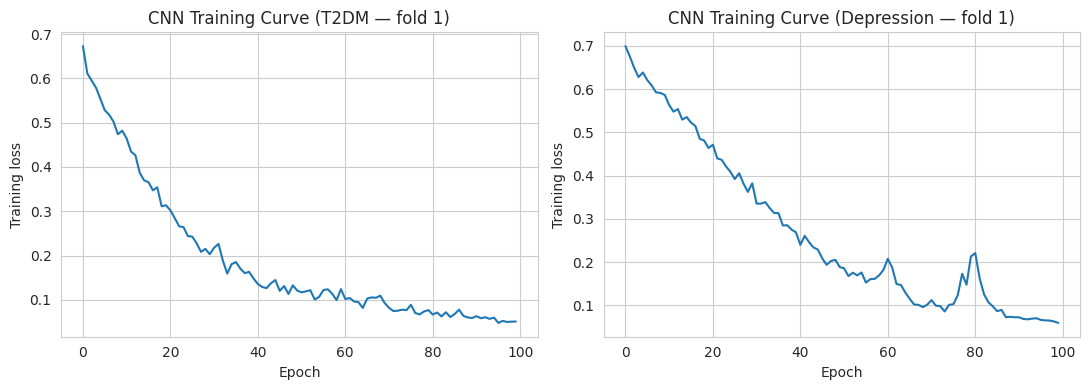

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (hist, title) in zip(axes, [(hist_t2dm, "T2DM — fold 1"), (hist_dep, "Depression — fold 1")]):
    ax.plot(hist)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Training loss")
    ax.set_title(f"CNN Training Curve ({title})")
plt.tight_layout()
plt.show()


### CNN vs. Best Classical Model — Immediate Comparison

Compare the CNN directly against the best classical model found in Section 7.


In [6]:
best_t2dm_classical = res_t2dm_classical.iloc[0]
best_dep_classical  = res_dep_classical.iloc[0]

print(f"{'Task':<12} {'Best Classical':<22} {'AUROC':>7}   {'CNN AUROC':>10}   Verdict")
print(f"{'T2DM':<12} {best_t2dm_classical['Model']:<22} {best_t2dm_classical['AUROC']:.3f}      {cnn_t2dm['AUROC']:.3f}      "
      f"{'CNN worse' if cnn_t2dm['AUROC'] < best_t2dm_classical['AUROC'] else 'CNN better'}")
print(f"{'Depression':<12} {best_dep_classical['Model']:<22} {best_dep_classical['AUROC']:.3f}      {cnn_dep['AUROC']:.3f}      "
      f"{'CNN worse' if cnn_dep['AUROC'] < best_dep_classical['AUROC'] else 'CNN better'}")


Task         Best Classical           AUROC    CNN AUROC   Verdict
T2DM         Random Forest          0.603      0.508      CNN worse
Depression   Random Forest          0.800      0.689      CNN worse


## 9. Attempt 2: Stacking Ensemble

A more principled "better architecture" idea for small tabular data: rather than
a single model, **stack** the three strongest classical models (Random Forest,
Gradient Boosting, XGBoost) and let a Logistic Regression meta-learner combine
their predictions. This can squeeze out a small amount of extra signal by
correcting each base model's blind spots — without the overfitting risk of a
deep net on this little data.


In [7]:
def stacking_cv(X, y, n_splits=5):
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    aucs, accs, f1s = [], [], []
    base_estimators = [
        ("rf", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE)),
        ("gb", GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE)),
        ("xgb", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                              eval_metric="logloss", random_state=RANDOM_STATE, verbosity=0)),
    ]
    for tr, te in cv.split(X, y):
        Xtr, Xte = X.iloc[tr], X.iloc[te]
        ytr, yte = y[tr], y[te]
        sm = SMOTE(random_state=RANDOM_STATE, k_neighbors=3)
        Xtr_r, ytr_r = sm.fit_resample(Xtr, ytr)

        stack = StackingClassifier(estimators=base_estimators,
                                    final_estimator=LogisticRegression(max_iter=1000),
                                    cv=3, stack_method="predict_proba")
        stack.fit(Xtr_r, ytr_r)
        proba = stack.predict_proba(Xte)[:, 1]
        pred = stack.predict(Xte)
        aucs.append(roc_auc_score(yte, proba))
        accs.append(accuracy_score(yte, pred))
        f1s.append(f1_score(yte, pred, zero_division=0))
    return {"AUROC": np.mean(aucs), "AUROC_std": np.std(aucs),
            "Accuracy": np.mean(accs), "F1": np.mean(f1s)}

stack_t2dm = stacking_cv(X_t2dm, y_t2dm)
stack_dep  = stacking_cv(X_dep, y_dep)

print("Stacking — T2DM:      ", {k: round(v,3) for k,v in stack_t2dm.items()})
print("Stacking — Depression:", {k: round(v,3) for k,v in stack_dep.items()})


Stacking — T2DM:       {'AUROC': np.float64(0.582), 'AUROC_std': np.float64(0.074), 'Accuracy': np.float64(0.813), 'F1': np.float64(0.094)}
Stacking — Depression: {'AUROC': np.float64(0.794), 'AUROC_std': np.float64(0.057), 'Accuracy': np.float64(0.734), 'F1': np.float64(0.805)}


## 10. Final Comparison — All Approaches, Both Tasks


,Model,AUROC,AUROC_std,Task
0,Random Forest,0.603,0.064,T2DM
1,Gradient Boosting,0.598,0.047,T2DM
2,Stacking Ensemble,0.582,0.074,T2DM
3,XGBoost,0.579,0.079,T2DM
4,Logistic Regression,0.545,0.111,T2DM
5,Decision Tree,0.520,0.088,T2DM
6,CNN (1D-Conv),0.508,0.143,T2DM
7,Naive Bayes,0.435,0.110,T2DM
8,SVM (RBF),0.422,0.069,T2DM
9,KNN,0.406,0.121,T2DM


,Model,AUROC,AUROC_std,Task
0,Random Forest,0.800,0.058,Depression
1,Stacking Ensemble,0.794,0.057,Depression
2,XGBoost,0.787,0.059,Depression
3,Gradient Boosting,0.761,0.066,Depression
4,SVM (RBF),0.746,0.065,Depression
5,Logistic Regression,0.731,0.072,Depression
6,KNN,0.705,0.070,Depression
7,CNN (1D-Conv),0.689,0.041,Depression
8,Naive Bayes,0.669,0.067,Depression
9,Decision Tree,0.644,0.060,Depression


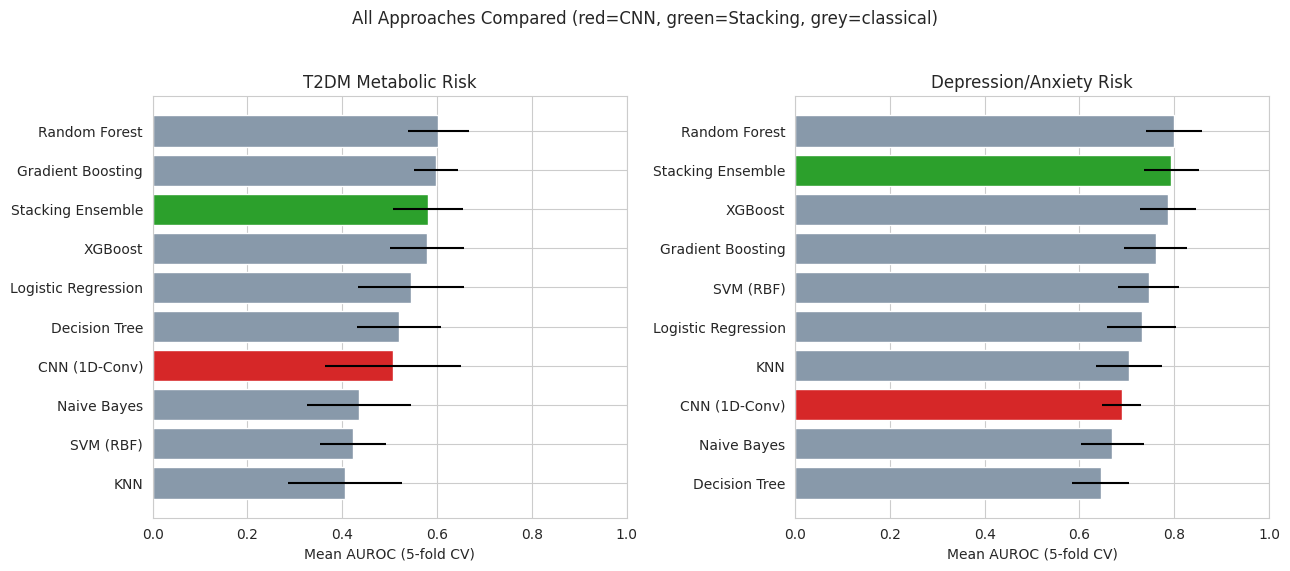

In [8]:
def combined_table(res_classical, cnn_res, stack_res, task_name):
    rows = res_classical[["Model","AUROC","AUROC_std"]].copy()
    rows = pd.concat([rows, pd.DataFrame([
        {"Model":"CNN (1D-Conv)", "AUROC":cnn_res["AUROC"], "AUROC_std":cnn_res["AUROC_std"]},
        {"Model":"Stacking Ensemble", "AUROC":stack_res["AUROC"], "AUROC_std":stack_res["AUROC_std"]},
    ])], ignore_index=True)
    rows["Task"] = task_name
    return rows.sort_values("AUROC", ascending=False).reset_index(drop=True)

full_t2dm = combined_table(res_t2dm_classical, cnn_t2dm, stack_t2dm, "T2DM")
full_dep  = combined_table(res_dep_classical, cnn_dep, stack_dep, "Depression")

display(full_t2dm.round(3))
display(full_dep.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
palette = {**{m: "#8899aa" for m in res_t2dm_classical["Model"]},
           "CNN (1D-Conv)": "#d62728", "Stacking Ensemble": "#2ca02c"}
for ax, (res, title) in zip(axes, [(full_t2dm, "T2DM Metabolic Risk"),
                                    (full_dep, "Depression/Anxiety Risk")]):
    colors = [palette.get(m, "#8899aa") for m in res["Model"]]
    ax.barh(res["Model"], res["AUROC"], xerr=res["AUROC_std"], color=colors)
    ax.set_xlabel("Mean AUROC (5-fold CV)")
    ax.set_xlim(0, 1)
    ax.set_title(title)
    ax.invert_yaxis()
plt.suptitle("All Approaches Compared (red=CNN, green=Stacking, grey=classical)", y=1.03)
plt.tight_layout()
plt.show()


## 11. Conclusion

**The CNN did not outperform the classical models on either task, and the
stacking ensemble roughly ties the best single classical model rather than
clearly beating it.** This is the expected outcome for a dataset this size and
shape, and it's worth stating plainly in a report rather than chasing a more
exotic architecture:

- **Why the CNN underperforms:** convolution assumes neighboring inputs are
  related; here the feature order is arbitrary (hormone levels, ratios,
  anthropometrics), so there's no local pattern to learn. With ~140 training
  patients per fold, a network with enough capacity to find *any* signal in an
  unordered feature vector is also large enough to memorize noise.
- **Why stacking doesn't clearly help:** Random Forest, Gradient Boosting, and
  XGBoost already make fairly correlated errors on this data (they're all
  tree ensembles seeing the same features), so there's limited complementary
  signal for a meta-learner to combine.
- **What would actually move the needle, in order of expected impact:**
  1. **More data** — the single biggest lever; n≈177 caps how much any model,
     simple or complex, can learn.
  2. **Better/more features** — e.g. an actual validated depression instrument
     (PHQ-9/GAD-7) instead of a proxy label, or additional biomarkers.
  3. **Feature selection**, not model complexity — your main manuscript
     pipeline's nested stability-selection already demonstrated this: a
     5-feature metabolic panel and 15-feature depression panel *outperformed*
     the full feature set (AUROC 0.650 vs. 0.617, and 0.704 vs. 0.667,
     respectively) using the same classical models. That's a bigger,
     more reliable gain than anything an architecture change delivered here.
  4. Careful hyperparameter tuning of the existing tree ensembles (grid/Bayesian
     search) is a smaller but easy further step.

For the class project write-up, this is a genuinely useful negative result:
it demonstrates you tested the "more complex model" hypothesis rigorously
rather than assuming it, and the data supports a clear methodological point —
architecture sophistication is not the bottleneck here, sample size and
feature quality are.
